# 第096讲可执行实验

先阅读lecture.md与lab.md，再重启内核从上到下执行。所有数据本地合成；不调用网络、GPU或付费模型。输出会覆盖本讲可再生的outputs/figures；探索实验请复制目录。

## 1 核对环境与工作目录
Notebook依赖同目录experiment.py。不要只下载.ipynb。

In [1]:
from pathlib import Path
import sys, json
import numpy as np
ROOT = Path.cwd()
assert (ROOT / "experiment.py").exists(), "请切换到本讲目录"
print("Python:", sys.version.split()[0], "NumPy:", np.__version__)

Python: 3.12.14 NumPy: 2.3.5


## 2 阅读实现并形成预测
下面列出核心实验源码。先对照讲义找出数据生成、模型或解析场、积分与评价四个位置。代码内注释解释形状、方向与边界。

In [2]:
import inspect
import experiment
print(inspect.getsource(experiment))

"""原创 CPU 教学实验。运行 python experiment.py；无需网络、GPU 或模型下载。"""
from pathlib import Path
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/dl-mpl")
import json, time
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
ROOT = Path(__file__).resolve().parent
OUT = ROOT / "outputs"
FIG = ROOT / "figures"
OUT.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / name, dpi=160); plt.close()

def score_cond(x,t,c):
    # 加性 Gaussian 噪声下，条件边缘仍为 Gaussian。
    return -(x-2*c)/(0.36+t)
def score_uncond(x,t):
    var=.36+t
    # sigmoid(4*x/var) 是正类责任概率。裁剪只用于数值稳定。
    r=1/(1+np.exp(np.clip(-4*x/var,-60,60)))
    return (2*(2*r-1)-x)/var

def sample(seed,w,steps=400,n=4000):
    rng=np.random.default_rng(seed); T=9.;h=T/steps
    # 从无条件 p_T 精确采样。对 w=1，它并非条件 p_T，需声明起点偏差。
    x=2*rng.choice([-1,1],n)+np.sqrt(.36+T)*rng.normal(size=n)
    for k in range(steps):
        t=T-k*h
        su=score_uncond(x,t);sc=sc

## 3 从头重新运行实验
这会真实生成样本、计算指标并重建图形；不是展示缓存结果。

In [3]:
results = experiment.main()

{
  "target_label": 1,
  "seed": 96,
  "steps": 400,
  "start_time": 9,
  "compression_mse_per_coordinate": 0.044823917722105915,
  "guidance": {
    "0": {
      "sign_consistency": 0.49,
      "mean": -0.024965527685805042,
      "std": 2.0829226359366273,
      "within_target_95": 0.469,
      "left_tail_coverage": 0.53275,
      "right_tail_coverage": 0.022
    },
    "1": {
      "sign_consistency": 0.999,
      "mean": 1.92503177101108,
      "std": 0.6002497724117524,
      "within_target_95": 0.94825,
      "left_tail_coverage": 0.065,
      "right_tail_coverage": 0.0375
    },
    "2": {
      "sign_consistency": 1.0,
      "mean": 2.0589840926367757,
      "std": 0.5612851382974885,
      "within_target_95": 0.9645,
      "left_tail_coverage": 0.02925,
      "right_tail_coverage": 0.048
    },
    "4": {
      "sign_consistency": 1.0,
      "mean": 2.1449917792874102,
      "std": 0.5550694596207139,
      "within_target_95": 0.95925,
      "left_tail_coverage": 0.01875,
    

## 4 核对持久化证据
先看每个数组的形状与是否有限，再解释指标。

In [4]:
saved = json.loads((ROOT / "outputs/metrics.json").read_text())
print(json.dumps(saved, ensure_ascii=False, indent=2))
with np.load(ROOT / "outputs/data.npz") as data:
    for key in data.files:
        a = data[key]
        print(key, a.shape, "finite:", bool(np.isfinite(a).all()))

{
  "target_label": 1,
  "seed": 96,
  "steps": 400,
  "start_time": 9,
  "compression_mse_per_coordinate": 0.044823917722105915,
  "guidance": {
    "0": {
      "sign_consistency": 0.49,
      "mean": -0.024965527685805042,
      "std": 2.0829226359366273,
      "within_target_95": 0.469,
      "left_tail_coverage": 0.53275,
      "right_tail_coverage": 0.022
    },
    "1": {
      "sign_consistency": 0.999,
      "mean": 1.92503177101108,
      "std": 0.6002497724117524,
      "within_target_95": 0.94825,
      "left_tail_coverage": 0.065,
      "right_tail_coverage": 0.0375
    },
    "2": {
      "sign_consistency": 1.0,
      "mean": 2.0589840926367757,
      "std": 0.5612851382974885,
      "within_target_95": 0.9645,
      "left_tail_coverage": 0.02925,
      "right_tail_coverage": 0.048
    },
    "4": {
      "sign_consistency": 1.0,
      "mean": 2.1449917792874102,
      "std": 0.5550694596207139,
      "within_target_95": 0.95925,
      "left_tail_coverage": 0.01875,
    

## 5 看完整图，不挑漂亮样本
图与讲义对应。观察不符合直觉的地方，结合指标解释。

01_compression.png


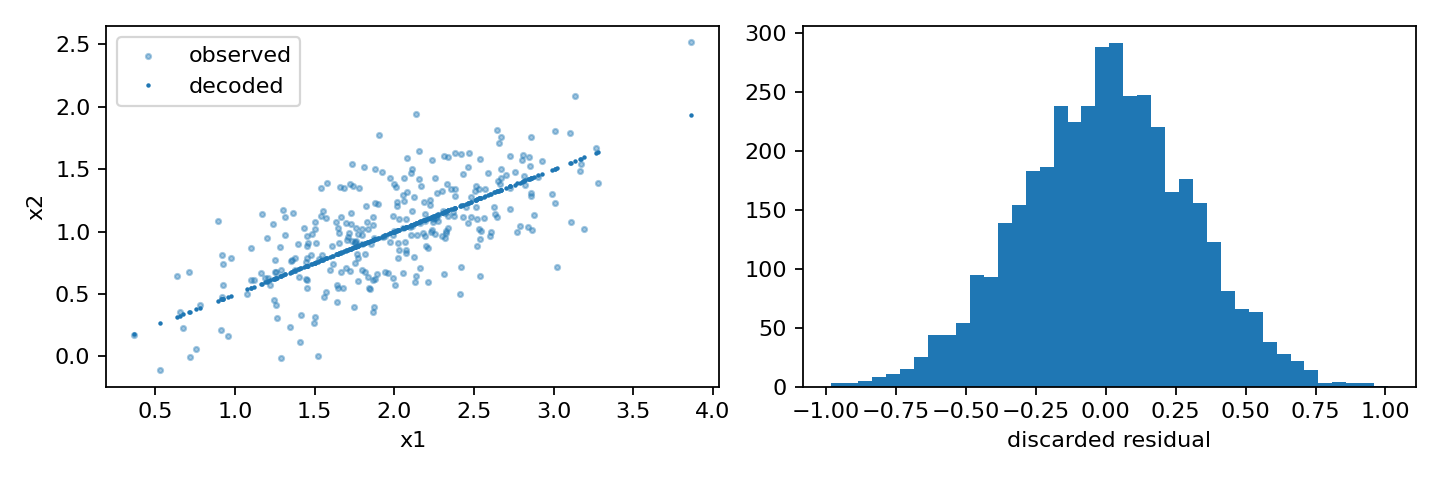

02_guidance.png


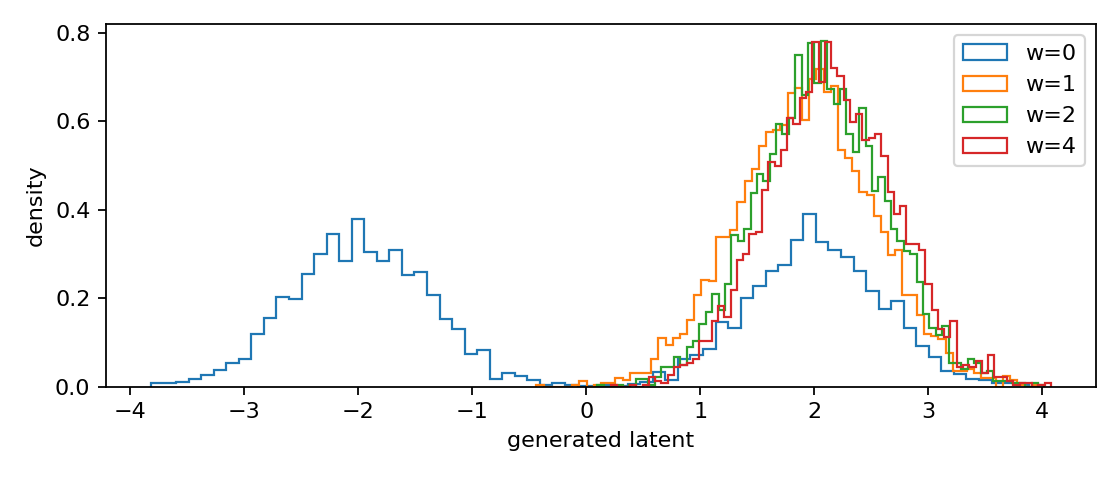

03_score.png


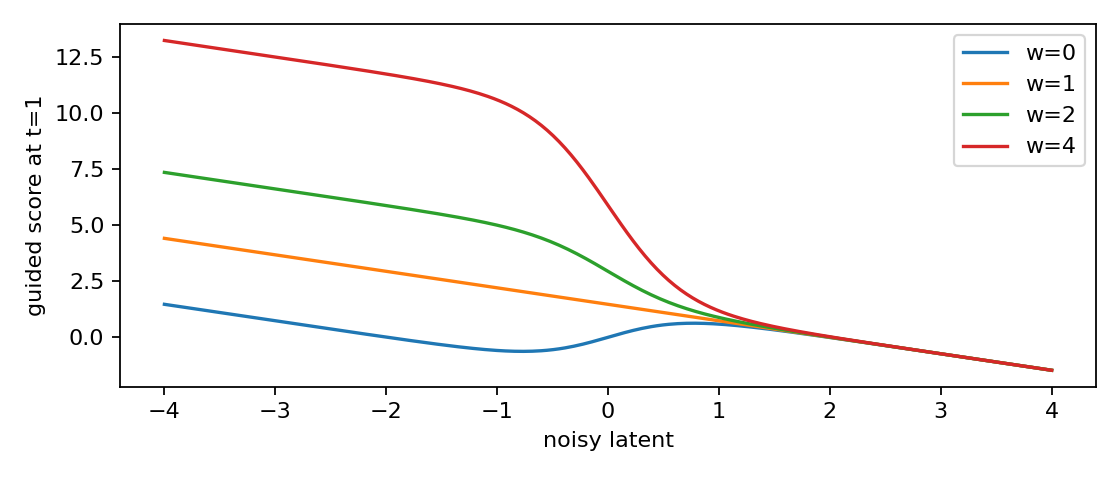

04_paths.png


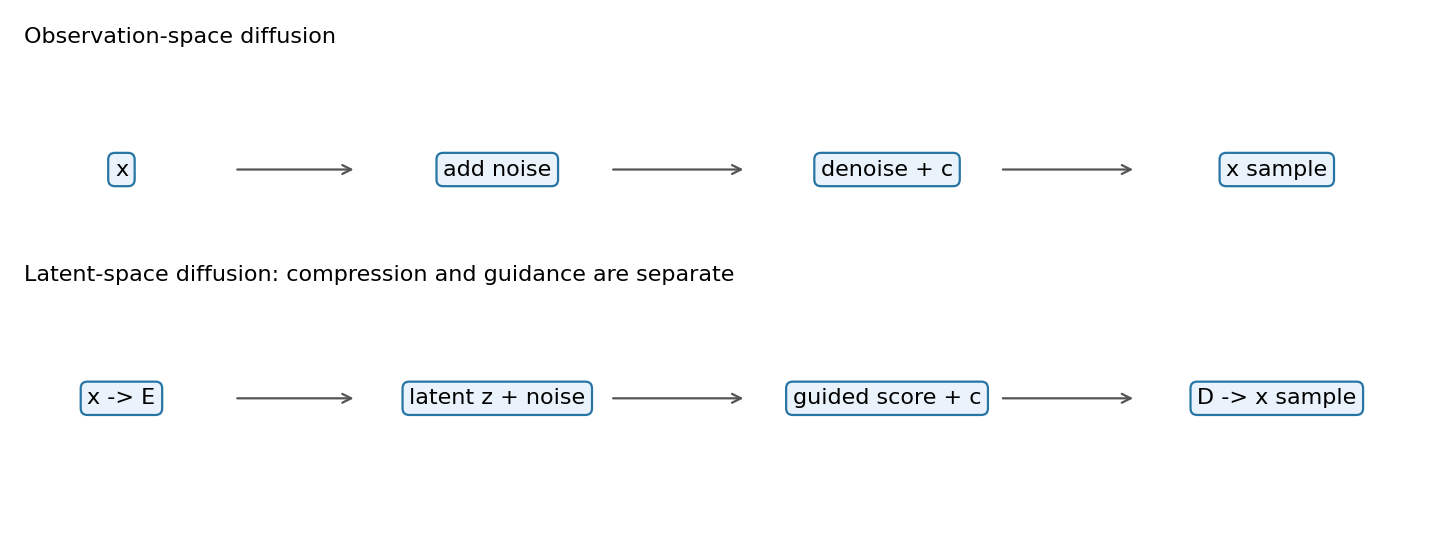

In [5]:
from IPython.display import display, Image
for figure in sorted((ROOT / "figures").glob("*.png")):
    print(figure.name)
    display(Image(filename=str(figure), width=760))

## 6 执行独立断言
测试通过只覆盖这些明确断言，不等于现实部署验证。之后按lab.md做一个受控变化。

In [6]:
import unittest
import tests
suite = unittest.defaultTestLoader.loadTestsFromModule(tests)
result = unittest.TextTestRunner(verbosity=2).run(suite)
assert result.wasSuccessful()

test_compression_and_generation (tests.TestExperiment.test_compression_and_generation) ... 

ok


test_conditional_value (tests.TestExperiment.test_conditional_value) ... 

ok


test_mixture_symmetry (tests.TestExperiment.test_mixture_symmetry) ... 

ok


test_score_finite_difference (tests.TestExperiment.test_score_finite_difference) ... 

ok


----------------------------------------------------------------------
Ran 4 tests in 0.015s

OK


## 反思与交付
写清本实验是学习模型还是解析score、样本数和种子、主要误差来源、实际结果与未检验范围。练习详解见answers.md。